# Covariance stabilization when N is close to T

The same dollar-neutral mean-variance problem is solved with three covariance estimates (sample, Ledoit–Wolf, eigenvalue clipping) on simulated data where the true covariance and the alpha are known. Only the estimate changes between methods, so every difference below comes from estimation error.

- **Efficiency** = true utility of the estimated portfolio ÷ true utility of the optimal portfolio. 1 is perfect, 0 is no better than holding nothing, and negative is worse than holding nothing.
- **Risk ratio** = predicted variance ÷ true variance of the chosen portfolio. Below 1 means the estimate understated the risk the optimizer took.

N = 100 assets, 20 seeds per ratio, medians. `scripts/n_close_to_t.py` prints the same numbers as the README table. Derivations are in `DERIVATIONS.md`, Part 1.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from robust_mvo.experiments import METHODS, run, summarize

RATIOS = (0.1, 0.25, 0.5, 0.75, 0.9, 1.0, 1.25, 1.5)
REGIMES = {
    "strong market factor": {"market_vol": 0.01, "style_vol": 0.005},
    "weak factors": {"market_vol": 0.003, "style_vol": 0.003},
}
results = {name: summarize(run(ratios=RATIOS, n_seeds=20, **kw)) for name, kw in REGIMES.items()}

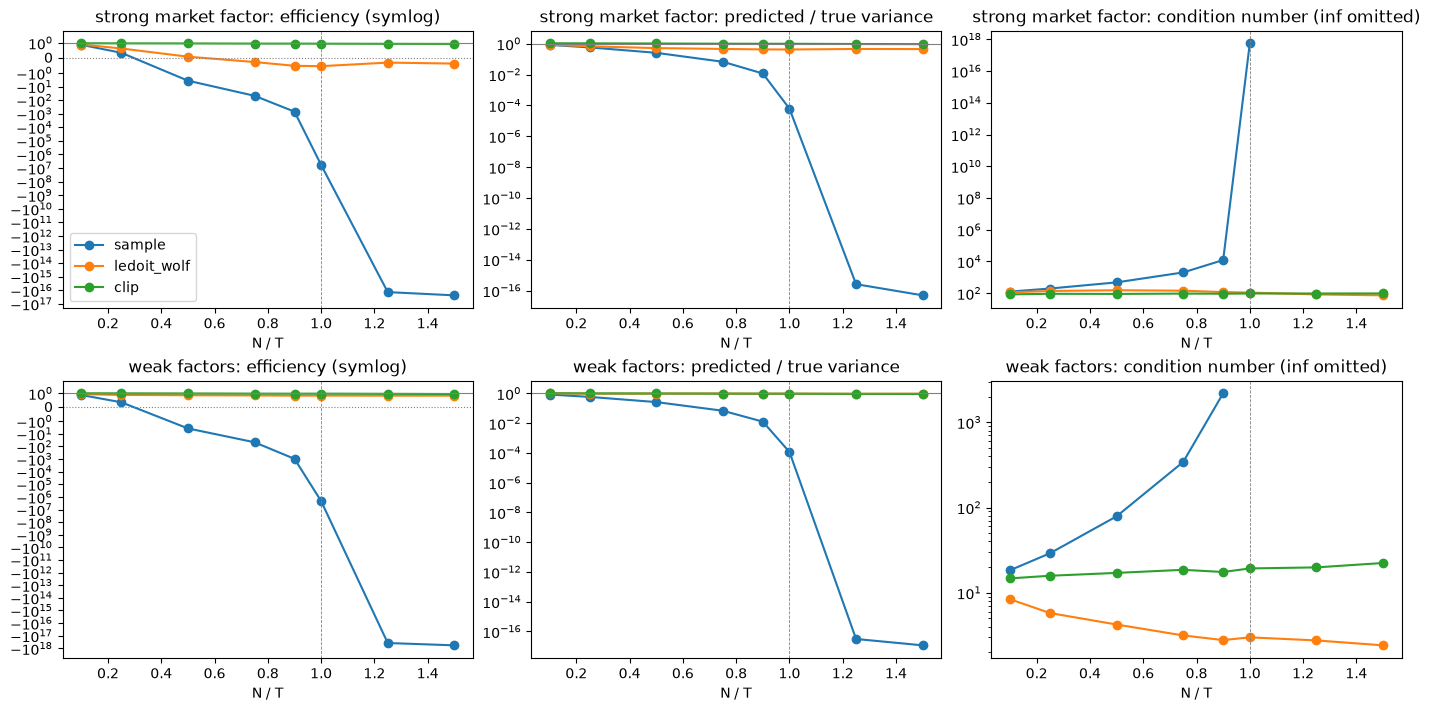

In [2]:
def series(summary, metric, method):
    return [s[metric] for s in summary if s["method"] == method]


fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
for row, (name, summary) in zip(axes, results.items(), strict=True):
    for method in METHODS:
        row[0].plot(RATIOS, series(summary, "efficiency", method), marker="o", label=method)
        row[1].plot(RATIOS, series(summary, "risk_ratio", method), marker="o", label=method)
        cond = np.array(series(summary, "cond", method))
        row[2].plot(RATIOS, np.where(np.isfinite(cond), cond, np.nan), marker="o", label=method)
    row[0].set_yscale("symlog", linthresh=1)
    row[0].axhline(1, color="grey", lw=0.8)
    row[0].axhline(0, color="grey", lw=0.8, ls=":")
    row[1].set_yscale("log")
    row[1].axhline(1, color="grey", lw=0.8)
    row[2].set_yscale("log")
    row[0].set_title(f"{name}: efficiency (symlog)")
    row[1].set_title(f"{name}: predicted / true variance")
    row[2].set_title(f"{name}: condition number (inf omitted)")
    for ax in row:
        ax.set_xlabel("N / T")
        ax.axvline(1, color="grey", lw=0.6, ls="--")
axes[0][0].legend()
plt.show()

In [3]:
for name, summary in results.items():
    print(name)
    print(f"{'N/T':>5} {'method':12} {'efficiency':>12} {'risk ratio':>11} {'cond':>10}")
    for s in summary:
        print(
            f"{s['q']:5g} {s['method']:12} {s['efficiency']:12.3g} "
            f"{s['risk_ratio']:11.3g} {s['cond']:10.3g}"
        )
    print()

strong market factor
  N/T method         efficiency  risk ratio       cond
  0.1 sample              0.866       0.832        126
  0.1 ledoit_wolf         0.886       0.861        113
  0.1 clip                0.969        1.06       84.6
 0.25 sample              0.337       0.574        198
 0.25 ledoit_wolf         0.623       0.673        139
 0.25 clip                0.963        1.05       92.2
  0.5 sample              -3.69       0.255        482
  0.5 ledoit_wolf        0.0799       0.515        154
  0.5 clip                0.957        1.03       90.4
 0.75 sample                -48       0.067   2.04e+03
 0.75 ledoit_wolf        -0.275       0.455        144
 0.75 clip                0.946       0.994       94.8
  0.9 sample               -705      0.0117   1.23e+04
  0.9 ledoit_wolf        -0.524       0.426        119
  0.9 clip                0.946       0.988       93.3
    1 sample          -5.96e+06     6.1e-05   5.61e+17
    1 ledoit_wolf         -0.55       0.419 

## Reading the results

**The sample covariance fails long before N = T.** By N/T = 0.5, efficiency is already negative in both regimes: the portfolio is worse than holding nothing. The optimizer puts the most weight on the smallest, most underestimated eigenvalues (DERIVATIONS 1.1), so predicted risk is a quarter of the true risk. At N ≥ T the matrix is singular. The PSD guard repairs it and the degradation chain reports level 0, a numerical success, but the weights are absurd. The chain protects against solver failure, not against a bad estimate. Bounding that damage takes either a stabilized estimate or a gross-leverage cap.

**Clipping keeps efficiency above 0.9 across the whole range.** It keeps the sample variances and the eigenvalues that stand out from the noise, and flattens the rest.

**Ledoit–Wolf (scaled-identity target) depends on the regime.** With weak factors it keeps efficiency between 0.82 and 0.93 and has the best conditioning of the three. With a strong market factor it does badly from N/T ≈ 0.5 onward: shrinking toward μI pulls the large market eigenvalue down and the individual variances toward their mean, so risk is understated by about half. Its median Frobenius error, the loss the method minimizes, is below the sample's from N/T = 0.25 on (`frob_err` in `summarize`), yet the portfolio is worse. A smaller matrix error does not mean a better portfolio.

**Limits of this comparison.** The data come from a factor model plus i.i.d. Gaussian noise, which is the "spiked" structure that eigenvalue clipping assumes. A comparison on real returns, on heavy-tailed noise, or against Ledoit–Wolf with a constant-correlation or single-index target could rank the methods differently. Those are not run here.